In [1]:
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression

from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [20]:
data = pd.read_csv('04_bank_customers.csv', sep=';')

print('Ukuran dataset:', data.shape)
data.head()

Ukuran dataset: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [21]:
print('Informasi dataset:')
data.info()

print('Statistik data angka:')
display(data.describe())

print('Nama seluruh kolom:')
print(data.columns)

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB
Statistik data angka:


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Nama seluruh kolom:
Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y'],
      dtype='str')


In [22]:
print('Jumlah data kosong setiap kolom:')
print(data.isnull().sum())

print('Jumlah baris duplikat:')
print(data.duplicated().sum())

Jumlah data kosong setiap kolom:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Jumlah baris duplikat:
0


y
no     39922
yes     5289
Name: count, dtype: int64


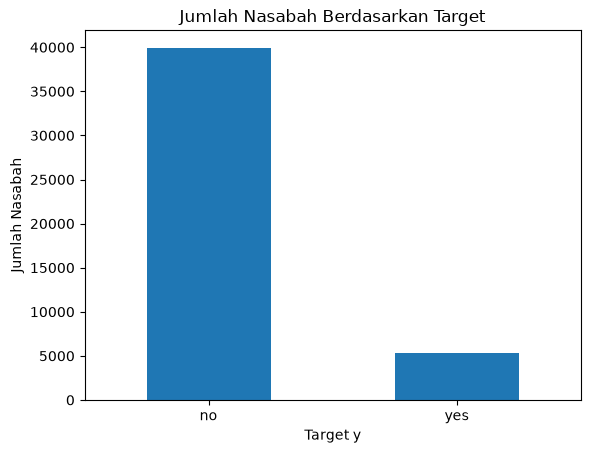

In [23]:
print(data['y'].value_counts())

data['y'].value_counts().plot(kind='bar')
plt.title('Jumlah Nasabah Berdasarkan Target')
plt.xlabel('Target y')
plt.ylabel('Jumlah Nasabah')
plt.xticks(rotation=0)
plt.show()

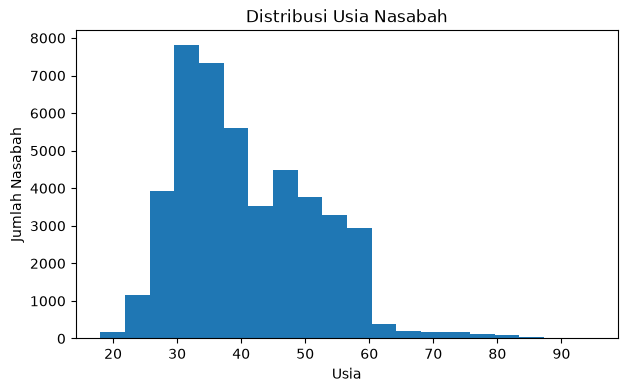

In [24]:
plt.figure(figsize=(7, 4))
plt.hist(data['age'], bins=20)
plt.title('Distribusi Usia Nasabah')
plt.xlabel('Usia')
plt.ylabel('Jumlah Nasabah')
plt.show()

C:\Users\adzkia nayla\AppData\Local\Temp\ipykernel_47732\875682580.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data['balance'], vert=False)


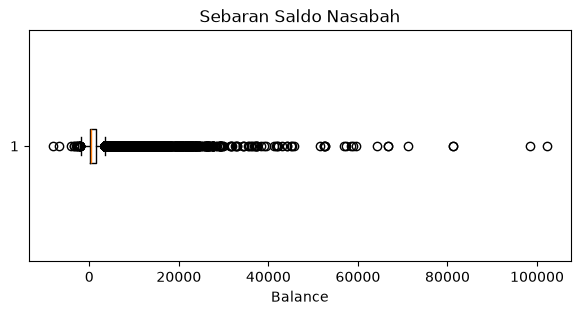

In [25]:
plt.figure(figsize=(7, 3))
plt.boxplot(data['balance'], vert=False)
plt.title('Sebaran Saldo Nasabah')
plt.xlabel('Balance')
plt.show()

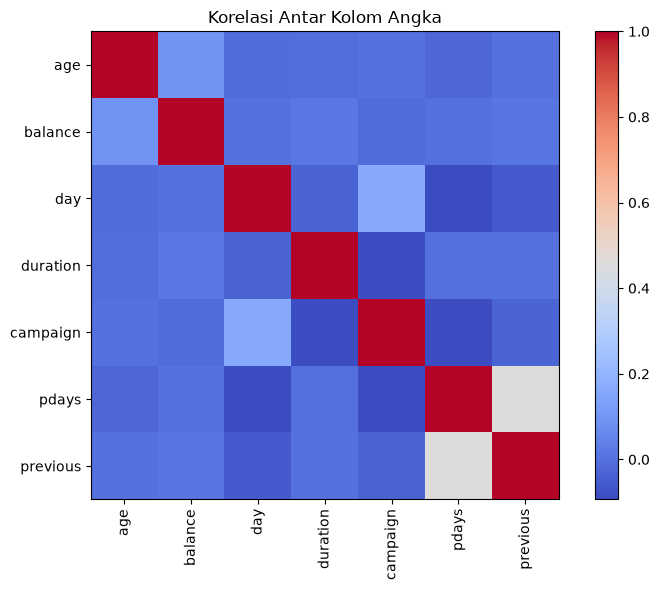

In [26]:
data_angka = data.select_dtypes(include=['int64', 'float64'])
korelasi = data_angka.corr()

plt.figure(figsize=(8, 6))
plt.imshow(korelasi, cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(korelasi.columns)), korelasi.columns, rotation=90)
plt.yticks(range(len(korelasi.columns)), korelasi.columns)
plt.title('Korelasi Antar Kolom Angka')
plt.tight_layout()
plt.show()

In [27]:
X = data.drop('y', axis=1)
y = data['y']

print('Jumlah fitur:', X.shape[1])
print('Jumlah target:', y.shape[0])

Jumlah fitur: 16
Jumlah target: 45211


In [28]:
kolom_kategori = X.select_dtypes(include=['object']).columns
kolom_angka = X.select_dtypes(exclude=['object']).columns

preprocessing = ColumnTransformer([
    ('kategori', OneHotEncoder(handle_unknown='ignore'), kolom_kategori),
    ('angka', 'passthrough', kolom_angka)
])

print('Kolom kategori:', list(kolom_kategori))
print('Kolom angka:', list(kolom_angka))

Kolom kategori: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Kolom angka: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


C:\Users\adzkia nayla\AppData\Local\Temp\ipykernel_47732\510073392.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  kolom_kategori = X.select_dtypes(include=['object']).columns


In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Jumlah data training:', len(X_train))
print('Jumlah data testing:', len(X_test))

Jumlah data training: 36168
Jumlah data testing: 9043


In [30]:
model_dt = Pipeline([
    ('preprocessing', preprocessing),
    ('model', DecisionTreeClassifier(max_depth=6, random_state=42))
])

model_dt.fit(X_train, y_train)

print('Model Decision Tree selesai dilatih.')

Model Decision Tree selesai dilatih.


In [31]:
prediksi_dt = model_dt.predict(X_test)

print('Contoh hasil prediksi:')
print(prediksi_dt[:10])

print('Jawaban sebenarnya:')
print(y_test.iloc[:10].values)

Contoh hasil prediksi:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']
Jawaban sebenarnya:
<ArrowStringArray>
['no', 'no', 'no', 'no', 'no', 'no', 'no', 'yes', 'no', 'no']
Length: 10, dtype: str


In [32]:
akurasi = accuracy_score(y_test, prediksi_dt)

print('Accuracy Decision Tree:', round(akurasi * 100, 2), '%')

Accuracy Decision Tree: 90.11 %


Confusion Matrix:
[[7689  296]
 [ 598  460]]


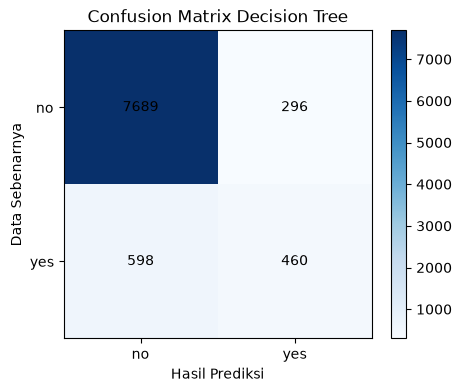

In [33]:
cm = confusion_matrix(y_test, prediksi_dt, labels=['no', 'yes'])

print('Confusion Matrix:')
print(cm)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix Decision Tree')
plt.xlabel('Hasil Prediksi')
plt.ylabel('Data Sebenarnya')
plt.xticks([0, 1], ['no', 'yes'])
plt.yticks([0, 1], ['no', 'yes'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.show()

In [34]:
print(classification_report(y_test, prediksi_dt))

              precision    recall  f1-score   support

          no       0.93      0.96      0.95      7985
         yes       0.61      0.43      0.51      1058

    accuracy                           0.90      9043
   macro avg       0.77      0.70      0.73      9043
weighted avg       0.89      0.90      0.89      9043



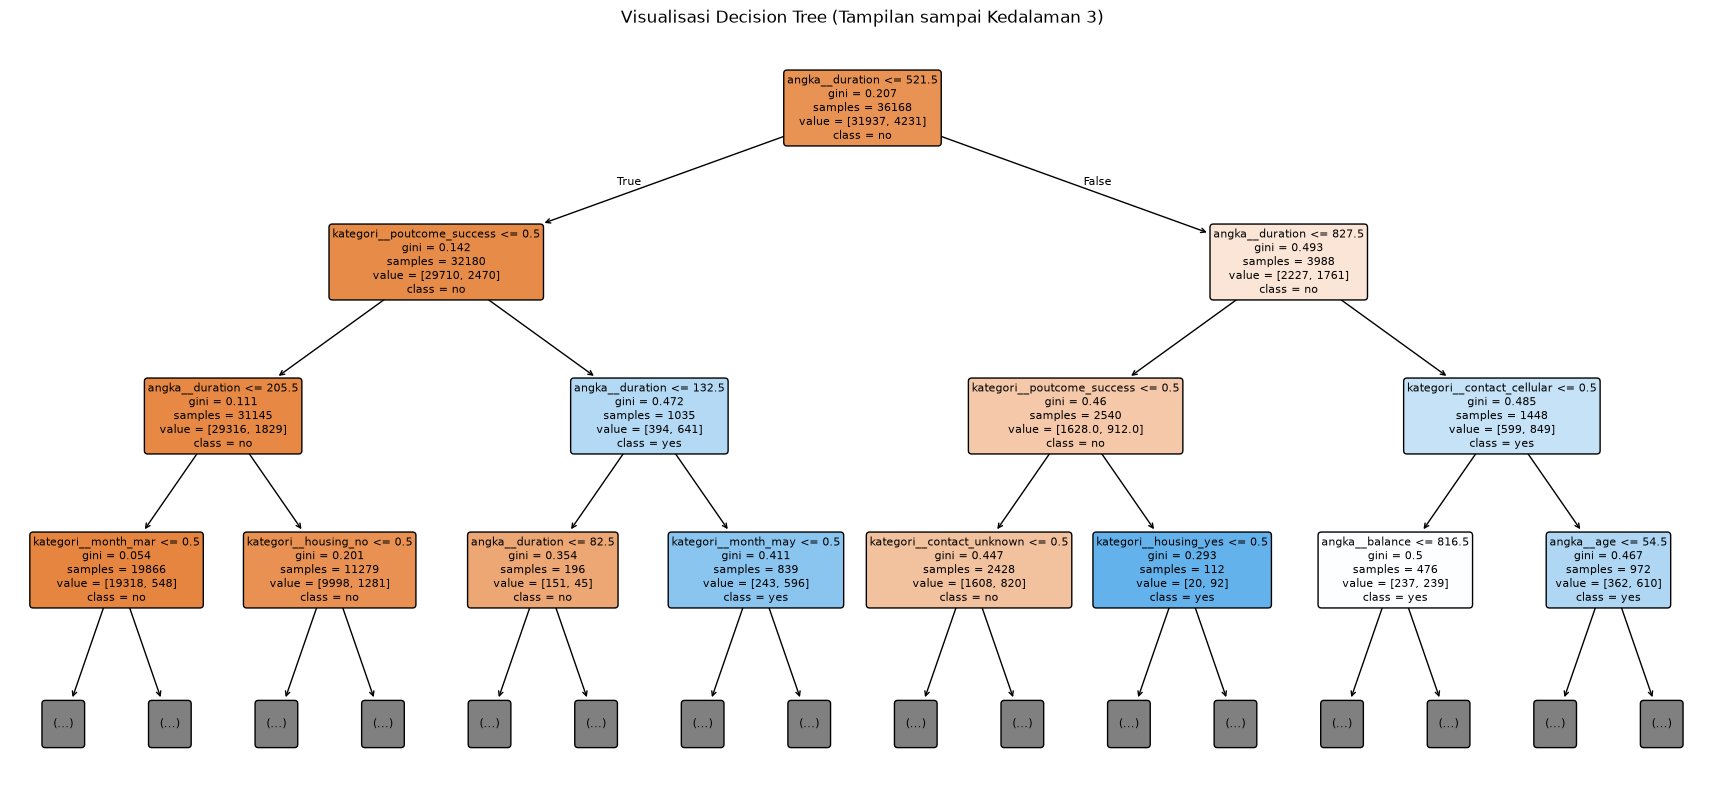

In [35]:
#Mengambil model decision tree dari pipeline
pohon = model_dt.named_steps['model']

#Mengambil nama fitur setelah proses One-Hot Encoding
nama_fitur = model_dt.named_steps['preprocessing'].get_feature_names_out()

plt.figure(figsize=(22, 10))
plot_tree(
    pohon,
    feature_names=nama_fitur,
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title('Visualisasi Decision Tree (Tampilan sampai Kedalaman 3)')
plt.show()

                    Nama Fitur  Nilai Pengaruh
47             angka__duration        0.520528
42  kategori__poutcome_success        0.276027
21        kategori__housing_no        0.041059
44                  angka__age        0.031699
35         kategori__month_mar        0.024192
49                angka__pdays        0.022009
28         kategori__month_apr        0.020155
27   kategori__contact_unknown        0.010747
46                  angka__day        0.009864
38         kategori__month_oct        0.009451


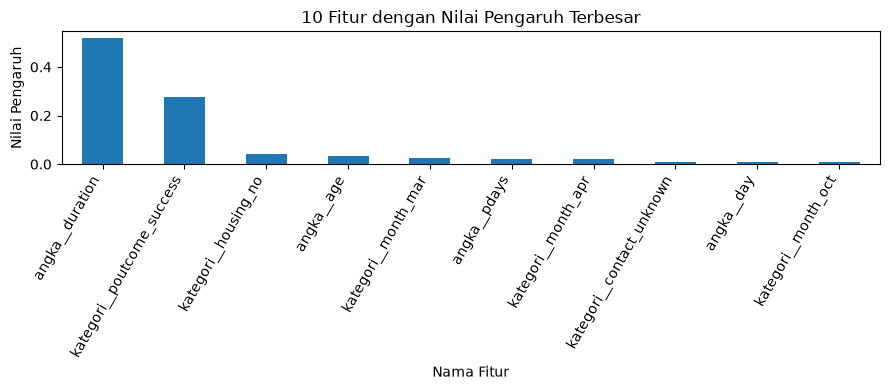

In [36]:
nilai_fitur = pohon.feature_importances_

tabel_fitur = pd.DataFrame({
    'Nama Fitur': nama_fitur,
    'Nilai Pengaruh': nilai_fitur
})

tabel_fitur = tabel_fitur.sort_values(
    by='Nilai Pengaruh',
    ascending=False
)

print(tabel_fitur.head(10))

tabel_fitur.head(10).plot(
    x='Nama Fitur',
    y='Nilai Pengaruh',
    kind='bar',
    legend=False,
    figsize=(9, 4)
)
plt.title('10 Fitur dengan Nilai Pengaruh Terbesar')
plt.xlabel('Nama Fitur')
plt.ylabel('Nilai Pengaruh')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [37]:
fitur_regresi = ['age', 'day', 'duration', 'campaign', 'pdays', 'previous']

X_regresi = data[fitur_regresi]
y_regresi = data['balance']

print('Fitur regresi:')
print(X_regresi.head())

print('Target balance:')
print(y_regresi.head())

Fitur regresi:
   age  day  duration  campaign  pdays  previous
0   58    5       261         1     -1         0
1   44    5       151         1     -1         0
2   33    5        76         1     -1         0
3   47    5        92         1     -1         0
4   33    5       198         1     -1         0
Target balance:
0    2143
1      29
2       2
3    1506
4       1
Name: balance, dtype: int64


In [38]:
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_regresi,
    y_regresi,
    test_size=0.2,
    random_state=42
)

print('Jumlah data training:', len(X_train_reg))
print('Jumlah data testing:', len(X_test_reg))

Jumlah data training: 36168
Jumlah data testing: 9043


In [39]:
model_lr = LinearRegression()

model_lr.fit(X_train_reg, y_train_reg)

print('Model Regresi Linear selesai dilatih.')

Model Regresi Linear selesai dilatih.


In [40]:
prediksi_lr = model_lr.predict(X_test_reg)

hasil_regresi = pd.DataFrame({
    'Balance Sebenarnya': y_test_reg.values,
    'Balance Prediksi': prediksi_lr
})

hasil_regresi.head(10)

,Balance Sebenarnya,Balance Prediksi
0,580,1338.432616
1,3644,1473.965407
2,538,932.816679
3,1773,1398.547199
4,217,1761.503315
5,1134,935.010374
6,1085,757.735602
7,127,1184.577003
8,3,1031.940403
9,258,1388.514678


In [41]:
nilai_r2 = r2_score(y_test_reg, prediksi_lr)
nilai_mae = mean_absolute_error(y_test_reg, prediksi_lr)
nilai_rmse = mean_squared_error(y_test_reg, prediksi_lr) ** 0.5

print('R-squared (R2):', round(nilai_r2, 4))
print('MAE:', round(nilai_mae, 2))
print('RMSE:', round(nilai_rmse, 2))

R-squared (R2): 0.0087
MAE: 1526.63
RMSE: 3116.31


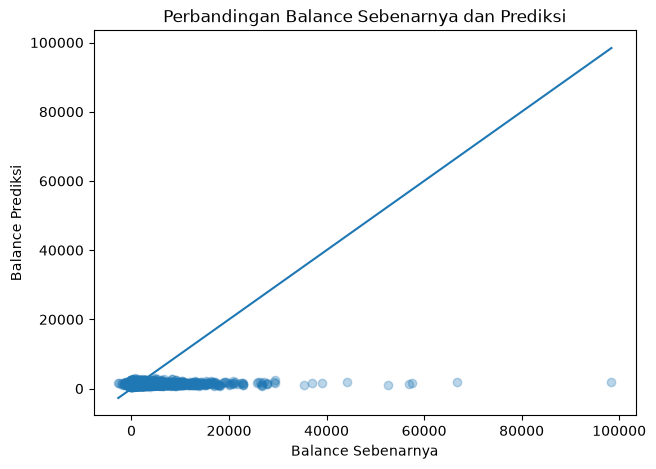

In [42]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, prediksi_lr, alpha=0.3)
plt.xlabel('Balance Sebenarnya')
plt.ylabel('Balance Prediksi')
plt.title('Perbandingan Balance Sebenarnya dan Prediksi')

# Garis pembanding
nilai_min = min(y_test_reg.min(), prediksi_lr.min())
nilai_max = max(y_test_reg.max(), prediksi_lr.max())
plt.plot([nilai_min, nilai_max], [nilai_min, nilai_max])

plt.show()